# 각인 가시성 측정 — imgsz 학습 입력 해상도별 각인 픽셀 보존도

처방 1(imgsz 1024) 정량 근거 확보. cache ROI 원본 → 합성 이미지 → 학습 입력 다운샘플 단계별로 각인 픽셀이 얼마나 살아남는지 측정.

핵심 질문: imgsz=640에서 각인이 픽셀 단위로 소실되는가? imgsz=1024로 가면 얼마나 보존되는가?

In [1]:
## 셋업 — 경로 + 폰트

from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import cv2
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# ── 경로 ──
ROOT = Path(r"D:\pill_detection")
CACHE_PATH = ROOT / "crops_cache.pkl"
SYNTH_DIR = ROOT / "data" / "synthetic_combined"
SYNTH_TRAIN_IMG = SYNTH_DIR / "images" / "train"
SYNTH_TRAIN_LBL = SYNTH_DIR / "labels" / "train"

ANALYSIS_DIR = ROOT / "analysis"
FIG_DIR = ANALYSIS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


# ── 한글 폰트 ──
candidates = ['Malgun Gothic', 'NanumGothic', 'Gulim']
available = {f.name for f in fm.fontManager.ttflist}
for name in candidates:
    if name in available:
        plt.rcParams['font.family'] = name
        print(f"한글 폰트: {name}")
        break
plt.rcParams['axes.unicode_minus'] = False


# ── 헬퍼 ──
def imread_kr(path):
    return cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)


# ── cache 로드 ──
print(f"\n[crops_cache.pkl 로드]")
with open(CACHE_PATH, "rb") as f:
    crops = pickle.load(f)
print(f"  ROI 수: {len(crops)}")
print(f"  크기: {CACHE_PATH.stat().st_size / 1024 / 1024:.0f} MB")


# 측정 대상 imgsz (학습 시 입력 해상도)
IMGSZ_TARGETS = [640, 1024, 1280]
# 합성 이미지 원본 해상도
SYNTH_IMG_W = 976
SYNTH_IMG_H = 1280
print(f"\n측정 대상 imgsz: {IMGSZ_TARGETS}")
print(f"합성 이미지 원본: {SYNTH_IMG_W} × {SYNTH_IMG_H}")

한글 폰트: Malgun Gothic

[crops_cache.pkl 로드]
  ROI 수: 7503
  크기: 2574 MB

측정 대상 imgsz: [640, 1024, 1280]
합성 이미지 원본: 976 × 1280


## 1. 각인 픽셀 정의 + 검증

각인 가시성을 픽셀 단위로 측정하려면 먼저 "각인 픽셀이란 무엇인가"부터 정해야 함.

**정의**: 알약 영역 안에서 Laplacian 절댓값이 상위 percentile 이상인 픽셀.

음각이든 양각이든 각인은 주변과 밝기 차이가 큼 → 2차 미분(Laplacian)이 큰 값을 가짐. 색이나 형태 같은 저주파 신호와 분리되는 고주파 영역.

**threshold**: 알약마다 각인 강도가 다르므로 절대값 임계 대신 알약 영역 내 percentile(90) 사용. 알약별 상대 기준.

**검증 ROI 1개**: cache 7503장 중 큰 쪽 상위 5%에서 무작위 1개(seed=42). 큰 ROI일수록 다음 셀에서 다운샘플 효과가 명확하게 보이고, 각인 검출 자체가 잘 되는지 직관 검증에도 유리함.

이 셀에서 확인할 것:
- crops 자료구조가 박제값(`img`, `w`, `h`)과 일치하는지
- Laplacian + percentile 조합이 실제 각인 부위를 잡는지 (시각)

crops 타입: list, 길이: 7503
항목 키: ['img', 'class_idx', 'w', 'h']
img 타입: Image
  PIL mode: RGBA, size(W×H): (169, 165)
w, h 예시: 169, 165

[검증 ROI 선택]
  key: 988
  meta w×h: 417 × 553
  numpy shape: (553, 417, 4), dtype: uint8

[픽셀 카운트]
  알약 영역: 95,284 px
  각인 영역: 11,341 px (11.90%)


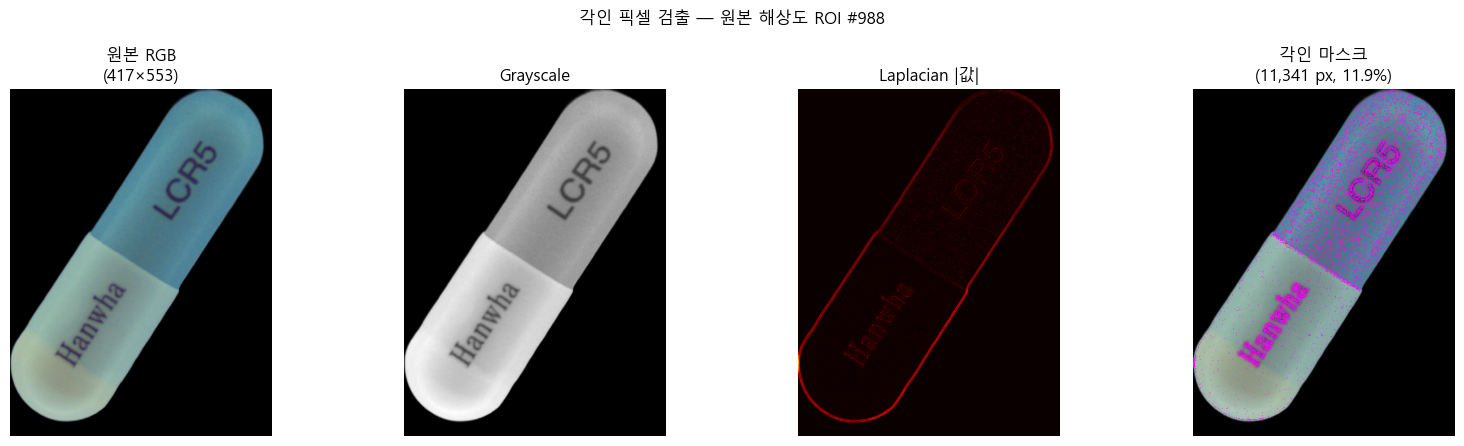


저장: D:\pill_detection\analysis\figures\imprint_01_definition.png


In [4]:
## 셀 3 — 각인 픽셀 정의 + cache ROI 1개 검증

# ── 자료구조 확인 (PIL Image 발견 후 정정) ──
if isinstance(crops, dict):
    sample_key = next(iter(crops))
    sample = crops[sample_key]
else:
    sample_key = 0
    sample = crops[0]

img_obj = sample['img']
print(f"crops 타입: {type(crops).__name__}, 길이: {len(crops)}")
print(f"항목 키: {list(sample.keys())}")
print(f"img 타입: {type(img_obj).__name__}")
if hasattr(img_obj, 'mode'):  # PIL Image
    print(f"  PIL mode: {img_obj.mode}, size(W×H): {img_obj.size}")
else:  # numpy
    print(f"  shape: {img_obj.shape}, dtype: {img_obj.dtype}")
print(f"w, h 예시: {sample['w']}, {sample['h']}")


# ── PIL → numpy RGBA 변환 헬퍼 ──
def pil_to_rgba(pil_img):
    """PIL Image → numpy (H, W, 4) uint8 RGBA. 모드가 RGBA가 아니면 변환."""
    if pil_img.mode != 'RGBA':
        pil_img = pil_img.convert('RGBA')
    return np.array(pil_img)


# ── 각인 픽셀 검출 함수 (RGBA 입력, 알파 침식 추가) ──
def extract_imprint_mask(rgba, ksize=3, percentile=90, erode_iter=2):
    """
    RGBA numpy ROI에서 각인 픽셀 마스크 생성.

    각인 = 알약 영역 (외곽 침식 후) 내 Laplacian 절댓값이 percentile 이상인 픽셀.

    erode_iter: 알파 외곽 침식 반복. rembg soft edge로 인한 boundary
                Laplacian 노이즈 차단. ksize=3 영향 범위(1px) 커버용 2회 기본.

    Args:
        rgba: (H, W, 4) uint8, RGB 순서 (PIL 표준)

    Returns:
        imprint_mask: (H, W) bool — 침식된 영역 내에서만 True
        gray: (H, W) uint8
        lap_abs: (H, W) float32
    """
    rgb = rgba[:, :, :3]
    alpha_raw = (rgba[:, :, 3] > 128).astype(np.uint8)

    # 외곽 침식 — 알파 boundary Laplacian 노이즈 제거
    kernel = np.ones((3, 3), np.uint8)
    alpha = cv2.erode(alpha_raw, kernel, iterations=erode_iter).astype(bool)

    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    lap = cv2.Laplacian(gray, cv2.CV_32F, ksize=ksize)
    lap_abs = np.abs(lap)

    pill_lap = lap_abs[alpha]
    if pill_lap.size == 0:
        return np.zeros_like(alpha), gray, lap_abs
    threshold = np.percentile(pill_lap, percentile)

    imprint_mask = (lap_abs >= threshold) & alpha
    return imprint_mask, gray, lap_abs


# ── 검증 ROI 선택: 큰 ROI 상위 5% 중 1개 (seed 고정) ──
SEED = 42
items = list(crops.items()) if isinstance(crops, dict) else list(enumerate(crops))
items_sorted = sorted(items, key=lambda kv: -(kv[1]['w'] * kv[1]['h']))
top_n = max(1, len(items_sorted) // 20)
rng = np.random.default_rng(SEED)
chosen_key, chosen = items_sorted[rng.integers(top_n)]

rgba = pil_to_rgba(chosen['img'])
print(f"\n[검증 ROI 선택]")
print(f"  key: {chosen_key}")
print(f"  meta w×h: {chosen['w']} × {chosen['h']}")
print(f"  numpy shape: {rgba.shape}, dtype: {rgba.dtype}")


# ── 각인 마스크 추출 ──
imprint_mask, gray, lap_abs = extract_imprint_mask(rgba, percentile=90)
alpha_mask = rgba[:, :, 3] > 128

n_pill_px = int(alpha_mask.sum())
n_imprint_px = int(imprint_mask.sum())
ratio = n_imprint_px / max(n_pill_px, 1)
print(f"\n[픽셀 카운트]")
print(f"  알약 영역: {n_pill_px:,} px")
print(f"  각인 영역: {n_imprint_px:,} px ({ratio*100:.2f}%)")


# ── 시각화 (4-패널) ──
rgb_view = rgba[:, :, :3]  # PIL 출신이라 이미 RGB. 변환 불필요.

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))

axes[0].imshow(rgb_view)
axes[0].set_title(f"원본 RGB\n({rgba.shape[1]}×{rgba.shape[0]})")
axes[0].axis('off')

axes[1].imshow(gray, cmap='gray')
axes[1].set_title("Grayscale")
axes[1].axis('off')

axes[2].imshow(lap_abs, cmap='hot')
axes[2].set_title("Laplacian |값|")
axes[2].axis('off')

overlay = rgb_view.copy()
overlay[imprint_mask] = [255, 0, 255]  # 마젠타
axes[3].imshow(overlay)
axes[3].set_title(f"각인 마스크\n({n_imprint_px:,} px, {ratio*100:.1f}%)")
axes[3].axis('off')

plt.suptitle(f"각인 픽셀 검출 — 원본 해상도 ROI #{chosen_key}", fontsize=12)
plt.tight_layout()

out = FIG_DIR / "imprint_01_definition.png"
plt.savefig(out, dpi=120, bbox_inches='tight')
plt.show()
print(f"\n저장: {out}")

## 2. 단계별 다운샘플 시뮬레이션 (1개 ROI)

학습 입력 imgsz별로 ROI가 얼마나 작아지는지, 그 결과 각인이 픽셀로 살아남는지 측정.

**다운샘플 scale**:
- 합성 이미지 원본: 976 × 1280 (long side 1280)
- imgsz=N 학습 시 long side가 N으로 리사이즈 → ROI도 동일 scale로 축소
  - imgsz 640: 0.5x
  - imgsz 1024: 0.8x
  - imgsz 1280: 1.0x

**측정 방식**: 원본 ROI에서 한 번, 다운샘플 ROI에서 다시 각인 마스크 추출.
다운샘플 후 비율 ÷ 원본 비율 = **보존율**.

학습 모델이 실제로 보는 건 다운샘플된 픽셀이므로 "원본 마스크를 어디로 옮겼나"가 아니라 "다운샘플된 이미지에서 각인이 다시 검출되는가"가 맞는 측정.

**리사이즈 방법**: PIL bilinear (학습 파이프라인 표준).

**erosion**: imgsz 무관 erode_iter=2 통일. 외곽선 노이즈는 항상 boundary 1-2 픽셀이라 imgsz 따라 안 바뀜.

imgsz별 scale:
  imgsz 640: 0.50x
  imgsz 1024: 0.80x
  imgsz 1280: 1.00x

[원본] 417×553, 알약 95,284px, 각인 11,341px (11.90%)
[imgsz  640] 208×276, 알약 23,713px, 각인 2,271px ( 9.58%) → 보존율 80.5%
[imgsz 1024] 334×442, 알약 60,995px, 각인 6,069px ( 9.95%) → 보존율 83.6%
[imgsz 1280] 417×553, 알약 95,284px, 각인 11,341px (11.90%) → 보존율 100.0%

[ROI #988 단계별 측정 결과]
 imgsz scale    size  pill_px  imprint_px  ratio_%  preservation_%
   640 0.50x 208×276    23713        2271     9.58            80.5
  1024 0.80x 334×442    60995        6069     9.95            83.6
  1280 1.00x 417×553    95284       11341    11.90           100.0


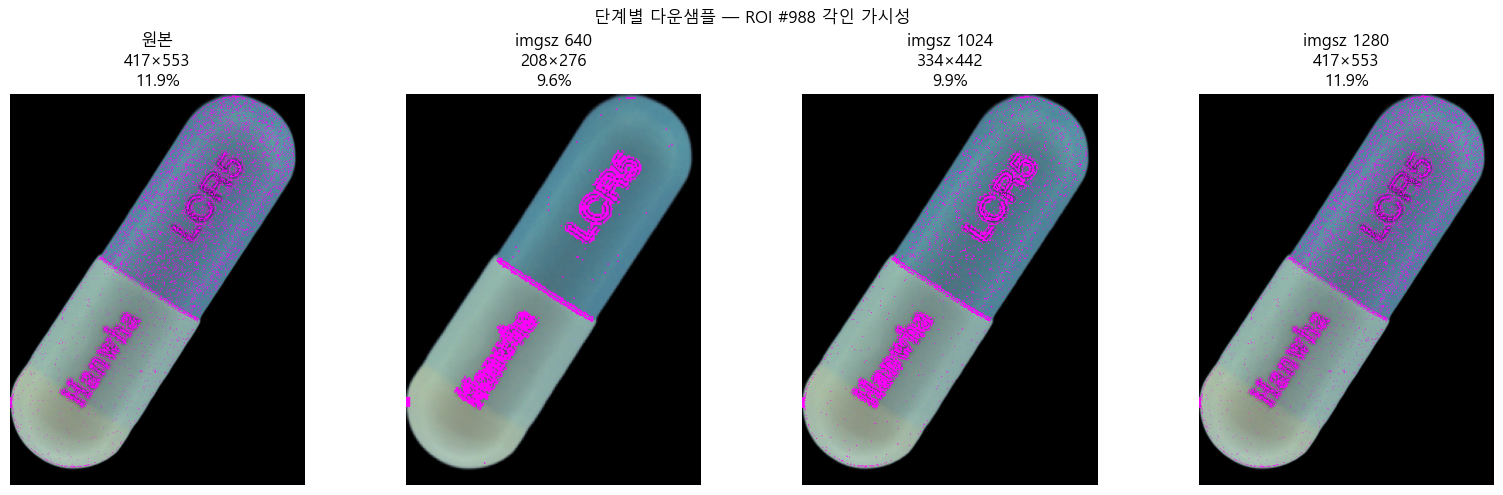


저장: D:\pill_detection\analysis\figures\imprint_02_downsample_single.png


In [5]:
## 셀 5 — 단계별 다운샘플 시뮬레이션 (1개 ROI)

# ── 다운샘플 scale 정의 ──
LONG_SIDE_ORIG = 1280  # 합성 이미지 long side (셀 1 박제값)
DOWNSAMPLE_TARGETS = {
    640: 640 / LONG_SIDE_ORIG,
    1024: 1024 / LONG_SIDE_ORIG,
    1280: 1280 / LONG_SIDE_ORIG,
}
print("imgsz별 scale:")
for imgsz, scale in DOWNSAMPLE_TARGETS.items():
    print(f"  imgsz {imgsz}: {scale:.2f}x")


# ── 원본 측정값 (이전 셀 재사용) ──
orig_h, orig_w = rgba.shape[:2]
orig_pill_px = n_pill_px
orig_imprint_px = n_imprint_px
orig_ratio = ratio
print(f"\n[원본] {orig_w}×{orig_h}, 알약 {orig_pill_px:,}px, 각인 {orig_imprint_px:,}px ({orig_ratio*100:.2f}%)")


# ── 단계별 다운샘플 + 각인 재추출 ──
pil_orig = chosen['img']  # PIL Image (셀 3에서 확인)

results = []
downsampled_data = {}

for imgsz, scale in DOWNSAMPLE_TARGETS.items():
    new_w = max(1, int(round(orig_w * scale)))
    new_h = max(1, int(round(orig_h * scale)))

    pil_ds = pil_orig.resize((new_w, new_h), Image.BILINEAR)
    rgba_ds = np.array(pil_ds)

    mask_ds, gray_ds, lap_ds = extract_imprint_mask(rgba_ds, percentile=90)
    alpha_ds = rgba_ds[:, :, 3] > 128

    pill_px = int(alpha_ds.sum())
    imprint_px = int(mask_ds.sum())
    ds_ratio = imprint_px / max(pill_px, 1)
    preservation = ds_ratio / orig_ratio if orig_ratio > 0 else 0

    results.append({
        'imgsz': imgsz,
        'scale': f"{scale:.2f}x",
        'size': f"{new_w}×{new_h}",
        'pill_px': pill_px,
        'imprint_px': imprint_px,
        'ratio_%': round(ds_ratio * 100, 2),
        'preservation_%': round(preservation * 100, 1),
    })
    downsampled_data[imgsz] = {
        'rgba': rgba_ds,
        'mask': mask_ds,
        'ratio': ds_ratio,
    }
    print(f"[imgsz {imgsz:>4d}] {new_w:>3d}×{new_h:>3d}, 알약 {pill_px:>6,}px, "
          f"각인 {imprint_px:>5,}px ({ds_ratio*100:>5.2f}%) → 보존율 {preservation*100:.1f}%")


# ── 결과 표 ──
df = pd.DataFrame(results)
print(f"\n[ROI #{chosen_key} 단계별 측정 결과]")
print(df.to_string(index=False))


# ── 시각화: 원본 + 3 imgsz (각인 마스크 오버레이) ──
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

overlay_orig = rgba[:, :, :3].copy()
overlay_orig[imprint_mask] = [255, 0, 255]
axes[0].imshow(overlay_orig)
axes[0].set_title(f"원본\n{orig_w}×{orig_h}\n{orig_ratio*100:.1f}%")
axes[0].axis('off')

for i, imgsz in enumerate(DOWNSAMPLE_TARGETS):
    d = downsampled_data[imgsz]
    rgba_ds = d['rgba']
    mask_ds = d['mask']
    overlay_ds = rgba_ds[:, :, :3].copy()
    overlay_ds[mask_ds] = [255, 0, 255]

    axes[i+1].imshow(overlay_ds)
    axes[i+1].set_title(
        f"imgsz {imgsz}\n{rgba_ds.shape[1]}×{rgba_ds.shape[0]}\n{d['ratio']*100:.1f}%"
    )
    axes[i+1].axis('off')

plt.suptitle(f"단계별 다운샘플 — ROI #{chosen_key} 각인 가시성", fontsize=12)
plt.tight_layout()

out = FIG_DIR / "imprint_02_downsample_single.png"
plt.savefig(out, dpi=120, bbox_inches='tight')
plt.show()
print(f"\n저장: {out}")

## 3. 측정 방식 보강 — 절대 강도 + Dual 임계 추가

이전 셀에서 percentile 90은 상대 임계라 다운샘플로 글자가 흐려져도 보존율이 높게 나오는 한계 발견. 시각(imgsz 640에서 Hanwha 거의 안 보임)과 수치(80.5%)가 어긋남.

**3개 지표 병행 측정:**

1. **A. 평균 Laplacian 강도** (`mean_lap_at_imprint`)
   - 각인 마스크 위치의 lap_abs 평균. 글자 흐려지면 이 값 직접 하락.
   - 절대 손실 정량화. 위치는 percentile로 잡되 강도는 절대값.

2. **B. Dual 임계 마스크 보존율**
   - 조건: `lap_abs >= ABS_THRESHOLD` AND `alpha_eroded`
   - 절대 임계 통과 픽셀만 카운트. 다운샘플로 lap_abs 떨어지면 픽셀 수 직접 감소.
   - 단일 수치로 보존율 표현.

3. **기존 percentile 마스크** (위치 시각화용 유지)

**ABS_THRESHOLD 결정**: 원본 ROI들의 imprint 픽셀 lap_abs 분포에서 25 percentile 사용. 너무 높으면 작은 ROI에서 모두 잘림, 너무 낮으면 다운샘플 효과 안 보임. 25 percentile = 약한 각인도 잡되 평균 노이즈는 거름.

검증 ROI는 두 개로 늘림: 큰 거(이전 #988) + 평균 크기 근처 1개. 평균 크기에서 imgsz 640 = 134×159 부근 시뮬되어 처방 1 가설("imgsz 640 시 137×137 손실") 직접 검증.

[ABS_THRESHOLD 캘리브레이션]
  샘플 50 ROI에서 imprint 픽셀 lap_abs 분포
  25 percentile = 16.00
  median = 24.00
  mean = 25.01

[검증 ROI 2개]
  큰 ROI: #988, 417×553
  평균 ROI: #7456, 323×257

[큰 ROI #988] 원본 417×553
  pill=91,598px, pct=11,341px (12.38%), abs=17,473px (19.08%), mean_lap=30.21
  imgsz 640: 208×276, pct=10.38% (83.8%) | abs=16.21% (85.0%) | mean_lap=58.95 (195.1%)
  imgsz 1024: 334×442, pct=10.45% (84.4%) | abs=13.22% (69.3%) | mean_lap=32.11 (106.3%)
  imgsz 1280: 417×553, pct=12.38% (100.0%) | abs=19.08% (100.0%) | mean_lap=30.21 (100.0%)

[평균 ROI #7456] 원본 323×257
  pill=37,450px, pct=4,519px (12.07%), abs=7,793px (20.81%), mean_lap=25.75
  imgsz 640: 162×128, pct=10.48% (86.8%) | abs=10.48% (50.4%) | mean_lap=21.32 (82.8%)
  imgsz 1024: 258×206, pct=13.84% (114.7%) | abs=9.03% (43.4%) | mean_lap=17.35 (67.4%)
  imgsz 1280: 323×257, pct=12.07% (100.0%) | abs=20.81% (100.0%) | mean_lap=25.75 (100.0%)

[전체 결과]
   roi  key imgsz    size  pill_px  pct_ratio_%  abs_ratio_%  mean_lap  pct

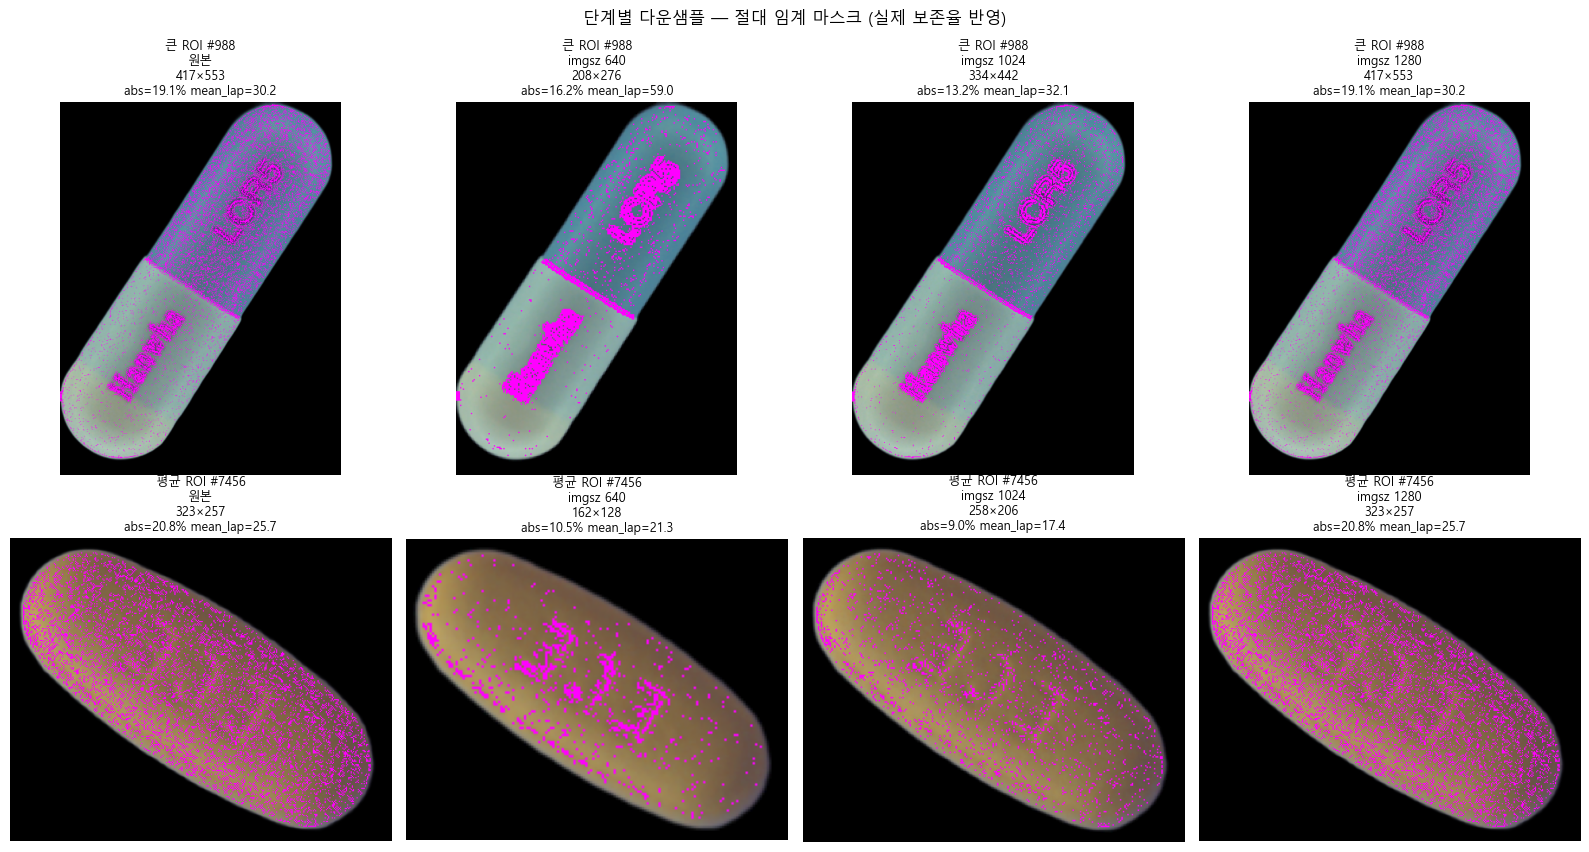


저장: D:\pill_detection\analysis\figures\imprint_03_dual_measure.png


In [6]:
## 셀 7 — Dual 측정 (percentile + 절대 강도) + ROI 2개 검증

# ── ABS_THRESHOLD 결정: 원본 cache 일부 ROI에서 imprint lap_abs 25 percentile ──
print("[ABS_THRESHOLD 캘리브레이션]")
SAMPLE_FOR_THRESHOLD = 50
rng_thr = np.random.default_rng(123)
sample_indices = rng_thr.choice(len(items), SAMPLE_FOR_THRESHOLD, replace=False)

all_imprint_lap_values = []
for idx in sample_indices:
    _, sample_item = items[idx]
    rgba_s = pil_to_rgba(sample_item['img'])
    mask_s, _, lap_abs_s = extract_imprint_mask(rgba_s, percentile=90)
    all_imprint_lap_values.extend(lap_abs_s[mask_s].tolist())

ABS_THRESHOLD = float(np.percentile(all_imprint_lap_values, 25))
print(f"  샘플 {SAMPLE_FOR_THRESHOLD} ROI에서 imprint 픽셀 lap_abs 분포")
print(f"  25 percentile = {ABS_THRESHOLD:.2f}")
print(f"  median = {np.median(all_imprint_lap_values):.2f}")
print(f"  mean = {np.mean(all_imprint_lap_values):.2f}")


# ── Dual 측정 함수 ──
def measure_imprint_dual(rgba, abs_threshold, ksize=3, percentile=90, erode_iter=2):
    """
    3개 지표 동시 측정:
    - imprint_mask_pct: percentile 마스크 (위치 시각화용)
    - imprint_mask_abs: 절대 임계 마스크 (보존율 측정용)
    - mean_lap_at_pct:  percentile 마스크 위치 평균 lap_abs (절대 강도)
    """
    rgb = rgba[:, :, :3]
    alpha_raw = (rgba[:, :, 3] > 128).astype(np.uint8)
    kernel = np.ones((3, 3), np.uint8)
    alpha = cv2.erode(alpha_raw, kernel, iterations=erode_iter).astype(bool)

    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    lap = cv2.Laplacian(gray, cv2.CV_32F, ksize=ksize)
    lap_abs = np.abs(lap)

    pill_px = int(alpha.sum())
    if pill_px == 0:
        empty = np.zeros_like(alpha)
        return {
            'pill_px': 0,
            'mask_pct': empty, 'imprint_pct_px': 0, 'ratio_pct': 0.0,
            'mask_abs': empty, 'imprint_abs_px': 0, 'ratio_abs': 0.0,
            'mean_lap_at_pct': 0.0,
        }

    pill_lap = lap_abs[alpha]
    pct_thr = np.percentile(pill_lap, percentile)
    mask_pct = (lap_abs >= pct_thr) & alpha
    mask_abs = (lap_abs >= abs_threshold) & alpha

    return {
        'pill_px': pill_px,
        'mask_pct': mask_pct,
        'imprint_pct_px': int(mask_pct.sum()),
        'ratio_pct': mask_pct.sum() / pill_px,
        'mask_abs': mask_abs,
        'imprint_abs_px': int(mask_abs.sum()),
        'ratio_abs': mask_abs.sum() / pill_px,
        'mean_lap_at_pct': float(lap_abs[mask_pct].mean()) if mask_pct.any() else 0.0,
    }


# ── 검증 ROI 2개: 기존 큰 거(#988) + 평균 크기 근처 1개 ──
# Q6 박제값: cache 평균 268×319. area = 85,492 근처 ROI 무작위 1개.
TARGET_AREA = 268 * 319
items_with_area = [(k, v, abs(v['w'] * v['h'] - TARGET_AREA)) for k, v in items]
items_close_to_avg = sorted(items_with_area, key=lambda x: x[2])[:200]  # area 근접 200개
rng_avg = np.random.default_rng(7)
avg_pick_idx = rng_avg.integers(len(items_close_to_avg))
avg_key, avg_item, _ = items_close_to_avg[avg_pick_idx]

CHECK_ROIS = [
    ('큰 ROI', chosen_key, chosen),
    ('평균 ROI', avg_key, avg_item),
]
print(f"\n[검증 ROI 2개]")
for label, k, v in CHECK_ROIS:
    print(f"  {label}: #{k}, {v['w']}×{v['h']}")


# ── 단계별 측정 ──
all_results = []
all_visuals = {}  # (label, imgsz) -> dict

for label, k, v in CHECK_ROIS:
    rgba_orig = pil_to_rgba(v['img'])
    pil_orig = v['img']
    orig_h_, orig_w_ = rgba_orig.shape[:2]

    # 원본
    m_orig = measure_imprint_dual(rgba_orig, ABS_THRESHOLD)
    base_pct = m_orig['ratio_pct']
    base_abs = m_orig['ratio_abs']
    base_mean_lap = m_orig['mean_lap_at_pct']

    print(f"\n[{label} #{k}] 원본 {orig_w_}×{orig_h_}")
    print(f"  pill={m_orig['pill_px']:,}px, "
          f"pct={m_orig['imprint_pct_px']:,}px ({base_pct*100:.2f}%), "
          f"abs={m_orig['imprint_abs_px']:,}px ({base_abs*100:.2f}%), "
          f"mean_lap={base_mean_lap:.2f}")

    all_results.append({
        'roi': label, 'key': k, 'imgsz': 'orig',
        'size': f"{orig_w_}×{orig_h_}",
        'pill_px': m_orig['pill_px'],
        'pct_ratio_%': round(base_pct*100, 2),
        'abs_ratio_%': round(base_abs*100, 2),
        'mean_lap': round(base_mean_lap, 2),
        'pct_preserve_%': 100.0,
        'abs_preserve_%': 100.0,
        'lap_preserve_%': 100.0,
    })
    all_visuals[(label, 'orig')] = {'rgba': rgba_orig, **m_orig}

    for imgsz, scale in DOWNSAMPLE_TARGETS.items():
        new_w = max(1, int(round(orig_w_ * scale)))
        new_h = max(1, int(round(orig_h_ * scale)))
        pil_ds = pil_orig.resize((new_w, new_h), Image.BILINEAR)
        rgba_ds = np.array(pil_ds)

        m_ds = measure_imprint_dual(rgba_ds, ABS_THRESHOLD)

        pct_preserve = m_ds['ratio_pct'] / base_pct if base_pct > 0 else 0
        abs_preserve = m_ds['ratio_abs'] / base_abs if base_abs > 0 else 0
        lap_preserve = m_ds['mean_lap_at_pct'] / base_mean_lap if base_mean_lap > 0 else 0

        print(f"  imgsz {imgsz}: {new_w}×{new_h}, "
              f"pct={m_ds['ratio_pct']*100:.2f}% ({pct_preserve*100:.1f}%) | "
              f"abs={m_ds['ratio_abs']*100:.2f}% ({abs_preserve*100:.1f}%) | "
              f"mean_lap={m_ds['mean_lap_at_pct']:.2f} ({lap_preserve*100:.1f}%)")

        all_results.append({
            'roi': label, 'key': k, 'imgsz': imgsz,
            'size': f"{new_w}×{new_h}",
            'pill_px': m_ds['pill_px'],
            'pct_ratio_%': round(m_ds['ratio_pct']*100, 2),
            'abs_ratio_%': round(m_ds['ratio_abs']*100, 2),
            'mean_lap': round(m_ds['mean_lap_at_pct'], 2),
            'pct_preserve_%': round(pct_preserve*100, 1),
            'abs_preserve_%': round(abs_preserve*100, 1),
            'lap_preserve_%': round(lap_preserve*100, 1),
        })
        all_visuals[(label, imgsz)] = {'rgba': rgba_ds, **m_ds}


# ── 결과 표 ──
df = pd.DataFrame(all_results)
print(f"\n[전체 결과]")
print(df.to_string(index=False))


# ── 시각화: 2 ROI × 4 imgsz, abs 마스크 오버레이 (실제 보존율 반영) ──
fig, axes = plt.subplots(2, 4, figsize=(16, 9))

for row, (label, k, v) in enumerate(CHECK_ROIS):
    for col, key_imgsz in enumerate(['orig'] + list(DOWNSAMPLE_TARGETS.keys())):
        d = all_visuals[(label, key_imgsz)]
        rgba_v = d['rgba']
        mask_v = d['mask_abs']  # 절대 임계 마스크
        overlay = rgba_v[:, :, :3].copy()
        overlay[mask_v] = [255, 0, 255]

        axes[row, col].imshow(overlay)
        title = (f"{label} #{k}\n"
                 f"{'원본' if key_imgsz == 'orig' else f'imgsz {key_imgsz}'}\n"
                 f"{rgba_v.shape[1]}×{rgba_v.shape[0]}\n"
                 f"abs={d['ratio_abs']*100:.1f}% mean_lap={d['mean_lap_at_pct']:.1f}")
        axes[row, col].set_title(title, fontsize=9)
        axes[row, col].axis('off')

plt.suptitle("단계별 다운샘플 — 절대 임계 마스크 (실제 보존율 반영)", fontsize=12)
plt.tight_layout()

out = FIG_DIR / "imprint_03_dual_measure.png"
plt.savefig(out, dpi=120, bbox_inches='tight')
plt.show()
print(f"\n저장: {out}")

## 4. resize 방법 영향 검증

이전 셀에서 PIL bilinear 다운샘플 시 mean_lap이 195%로 폭증. bilinear가 특정 scale에서 high-frequency 증폭하는 artifact 의심.

cv2 INTER_AREA는 다운샘플 표준(픽셀 평균화) — bilinear와 다른 동작.

같은 ROI 2개에 두 방법 적용해서 lap 패턴 비교. 한쪽이 명확히 단조 감소 보이면 그 방법으로 통일.

[resize 방법 × imgsz 비교]
   roi  key       method  imgsz    size  pct_ratio_%  abs_ratio_%  mean_lap  pct_preserve_%  abs_preserve_%  lap_preserve_%
 큰 ROI  988 PIL_BILINEAR    640 208×276        10.38        16.21     58.95            83.8            85.0           195.1
 큰 ROI  988 PIL_BILINEAR   1024 334×442        10.45        13.22     32.11            84.4            69.3           106.3
 큰 ROI  988 PIL_BILINEAR   1280 417×553        12.38        19.08     30.21           100.0           100.0           100.0
 큰 ROI  988     CV2_AREA    640 208×276        10.20        18.44     62.06            82.4            96.7           205.4
 큰 ROI  988     CV2_AREA   1024 334×442        11.35        14.28     31.66            91.7            74.9           104.8
 큰 ROI  988     CV2_AREA   1280 417×553        12.38        19.08     30.21           100.0           100.0           100.0
평균 ROI 7456 PIL_BILINEAR    640 162×128        10.48        10.48     21.32            86.8            50.4  

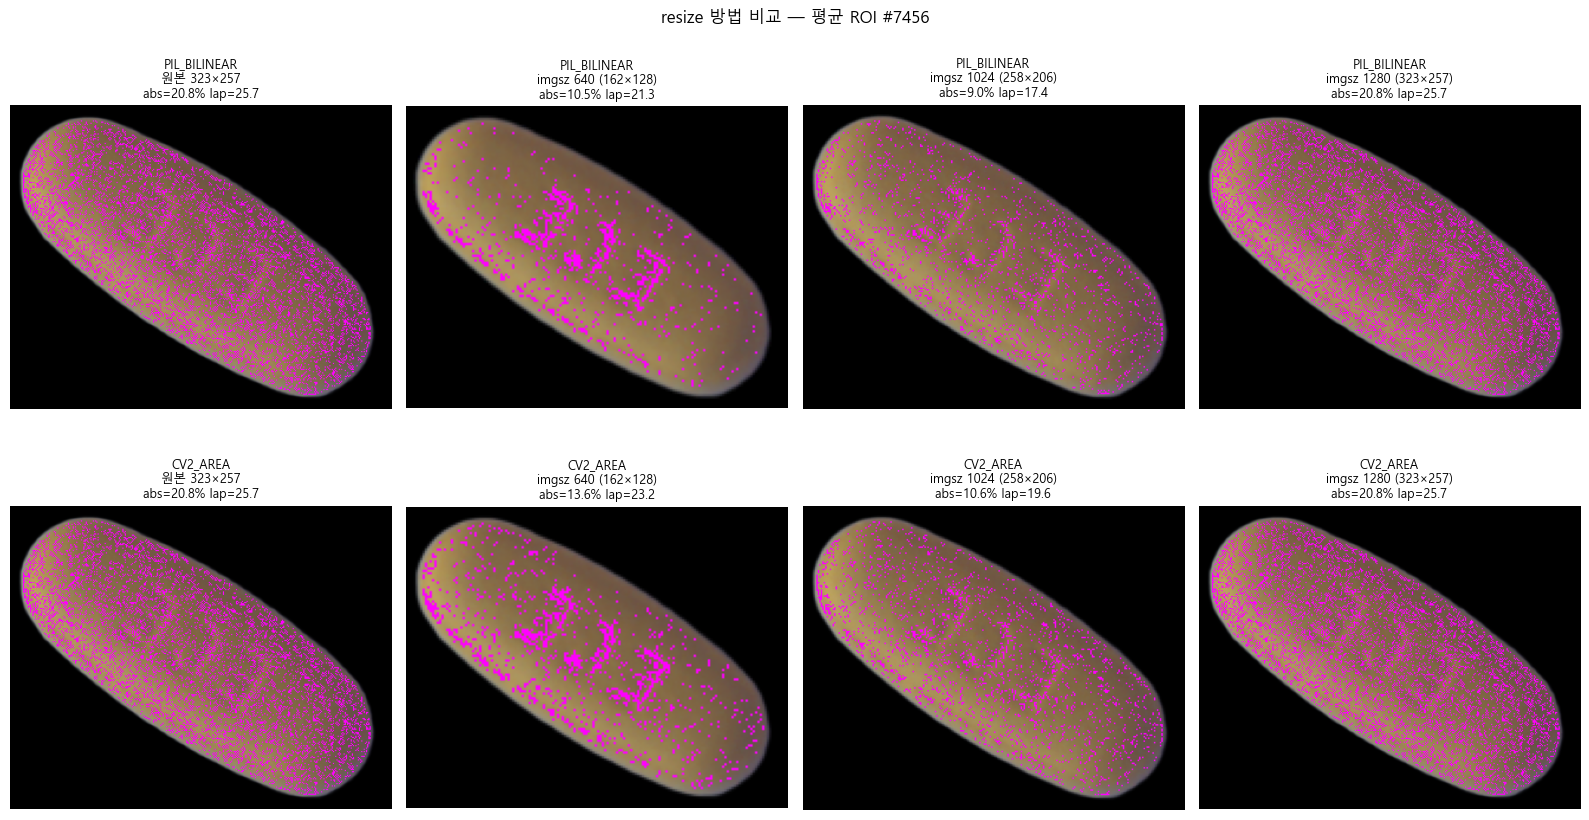


저장: D:\pill_detection\analysis\figures\imprint_04_resize_method.png


In [7]:
## 셀 9 — resize 방법 비교 (PIL bilinear vs cv2 INTER_AREA)

# ── 비교 함수 ──
def resize_pil_bilinear(pil_img, new_w, new_h):
    return np.array(pil_img.resize((new_w, new_h), Image.BILINEAR))

def resize_cv2_area(pil_img, new_w, new_h):
    arr = np.array(pil_img)  # RGBA
    return cv2.resize(arr, (new_w, new_h), interpolation=cv2.INTER_AREA)

RESIZE_METHODS = {
    'PIL_BILINEAR': resize_pil_bilinear,
    'CV2_AREA': resize_cv2_area,
}


# ── 측정 ──
compare_results = []

for label, k, v in CHECK_ROIS:
    pil_orig = v['img']
    rgba_orig = pil_to_rgba(pil_orig)
    orig_h_, orig_w_ = rgba_orig.shape[:2]
    m_orig = measure_imprint_dual(rgba_orig, ABS_THRESHOLD)
    base_pct = m_orig['ratio_pct']
    base_abs = m_orig['ratio_abs']
    base_mean = m_orig['mean_lap_at_pct']

    for method_name, resize_fn in RESIZE_METHODS.items():
        for imgsz, scale in DOWNSAMPLE_TARGETS.items():
            new_w = max(1, int(round(orig_w_ * scale)))
            new_h = max(1, int(round(orig_h_ * scale)))
            rgba_ds = resize_fn(pil_orig, new_w, new_h)
            m_ds = measure_imprint_dual(rgba_ds, ABS_THRESHOLD)

            compare_results.append({
                'roi': label, 'key': k, 'method': method_name, 'imgsz': imgsz,
                'size': f"{new_w}×{new_h}",
                'pct_ratio_%': round(m_ds['ratio_pct']*100, 2),
                'abs_ratio_%': round(m_ds['ratio_abs']*100, 2),
                'mean_lap': round(m_ds['mean_lap_at_pct'], 2),
                'pct_preserve_%': round(m_ds['ratio_pct']/base_pct*100, 1) if base_pct>0 else 0,
                'abs_preserve_%': round(m_ds['ratio_abs']/base_abs*100, 1) if base_abs>0 else 0,
                'lap_preserve_%': round(m_ds['mean_lap_at_pct']/base_mean*100, 1) if base_mean>0 else 0,
            })


# ── 표 ──
df_cmp = pd.DataFrame(compare_results)
print("[resize 방법 × imgsz 비교]")
print(df_cmp.to_string(index=False))


# ── 단조성 체크 (imgsz 640 → 1024 → 1280) ──
print("\n[단조 감소 체크 — abs_preserve, lap_preserve가 imgsz↓ 일수록 낮은가]")
for label, k, _ in CHECK_ROIS:
    for method_name in RESIZE_METHODS:
        sub = df_cmp[(df_cmp['roi']==label) & (df_cmp['method']==method_name)].sort_values('imgsz')
        abs_vals = sub['abs_preserve_%'].tolist()
        lap_vals = sub['lap_preserve_%'].tolist()
        abs_mono = all(abs_vals[i] <= abs_vals[i+1] for i in range(len(abs_vals)-1))
        lap_mono = all(lap_vals[i] <= lap_vals[i+1] for i in range(len(lap_vals)-1))
        print(f"  {label} #{k} / {method_name}: "
              f"abs {abs_vals} {'✓ 단조' if abs_mono else '✗ 비단조'} | "
              f"lap {lap_vals} {'✓ 단조' if lap_mono else '✗ 비단조'}")


# ── 시각: 평균 ROI에서 두 방법 비교 (640만, 차이 가장 큼) ──
fig, axes = plt.subplots(2, 4, figsize=(16, 9))
label_avg, k_avg, v_avg = CHECK_ROIS[1]
pil_avg = v_avg['img']
rgba_avg_orig = pil_to_rgba(pil_avg)
m_avg_orig = measure_imprint_dual(rgba_avg_orig, ABS_THRESHOLD)

for col, key_imgsz in enumerate(['orig'] + list(DOWNSAMPLE_TARGETS.keys())):
    if key_imgsz == 'orig':
        for row, method_name in enumerate(RESIZE_METHODS):
            overlay = rgba_avg_orig[:, :, :3].copy()
            overlay[m_avg_orig['mask_abs']] = [255, 0, 255]
            axes[row, col].imshow(overlay)
            axes[row, col].set_title(f"{method_name}\n원본 {rgba_avg_orig.shape[1]}×{rgba_avg_orig.shape[0]}\n"
                                     f"abs={m_avg_orig['ratio_abs']*100:.1f}% lap={m_avg_orig['mean_lap_at_pct']:.1f}",
                                     fontsize=9)
            axes[row, col].axis('off')
    else:
        scale = DOWNSAMPLE_TARGETS[key_imgsz]
        nw = max(1, int(round(rgba_avg_orig.shape[1] * scale)))
        nh = max(1, int(round(rgba_avg_orig.shape[0] * scale)))
        for row, (method_name, resize_fn) in enumerate(RESIZE_METHODS.items()):
            rgba_ds = resize_fn(pil_avg, nw, nh)
            m_ds = measure_imprint_dual(rgba_ds, ABS_THRESHOLD)
            overlay = rgba_ds[:, :, :3].copy()
            overlay[m_ds['mask_abs']] = [255, 0, 255]
            axes[row, col].imshow(overlay)
            axes[row, col].set_title(f"{method_name}\nimgsz {key_imgsz} ({nw}×{nh})\n"
                                     f"abs={m_ds['ratio_abs']*100:.1f}% lap={m_ds['mean_lap_at_pct']:.1f}",
                                     fontsize=9)
            axes[row, col].axis('off')

plt.suptitle(f"resize 방법 비교 — 평균 ROI #{k_avg}", fontsize=12)
plt.tight_layout()

out = FIG_DIR / "imprint_04_resize_method.png"
plt.savefig(out, dpi=120, bbox_inches='tight')
plt.show()
print(f"\n저장: {out}")

## 5. 비단조 원인 — 의심 가설 4가지 동시 검증

이전 셀에서 PIL/CV2 둘 다 비단조 확인. resize 방법 원인 아님.

남은 의심:
- ksize=3 고정의 scale 의존성 (다운샘플 시 더 적은 픽셀 덮음 → 디테일 압축)
- "다운샘플 후 그 해상도 측정"이 학습 의미와 안 맞음 (모델이 보는 정보 손실 ≠ 픽셀 수 변화)

**4가지 측정 방법 동시 비교:**
- M1: 다운샘플 + ksize 3 (baseline)
- M2: 다운→업 (원본 해상도 복원) + ksize 3 (이미지 quality 측정 표준)
- M3: 다운샘플 + ksize 5 (커널 scale 보정 시도)
- M4: 다운→업 + ksize 5

원본 baseline은 ksize 3 통일.
어느 방법이 단조 감소 보이는지 = 그 방법이 옳은 측정.

[4 방법 × 2 ROI × 3 imgsz 측정]
   roi  key     method  imgsz  pct_%  abs_%    lap  pct_pres  abs_pres  lap_pres
 큰 ROI  988   M1_DS_k3    640  10.20  18.44  62.06      82.4      96.7     205.4
 큰 ROI  988   M1_DS_k3   1024  11.35  14.28  31.66      91.7      74.9     104.8
 큰 ROI  988   M1_DS_k3   1280  12.38  19.08  30.21     100.0     100.0     100.0
 큰 ROI  988 M2_DSUP_k3    640  11.25   5.63  19.97      90.8      29.5      66.1
 큰 ROI  988 M2_DSUP_k3   1024  12.52   6.95  20.26     101.2      36.4      67.1
 큰 ROI  988 M2_DSUP_k3   1280  12.38  19.08  30.21     100.0     100.0     100.0
 큰 ROI  988   M3_DS_k5    640  10.03  78.22 684.25      81.0     410.1    2264.9
 큰 ROI  988   M3_DS_k5   1024  10.05  77.85 409.71      81.1     408.1    1356.1
 큰 ROI  988   M3_DS_k5   1280  10.14  80.07 320.04      81.9     419.7    1059.3
 큰 ROI  988 M4_DSUP_k5    640  10.04  64.21 284.96      81.1     336.6     943.2
 큰 ROI  988 M4_DSUP_k5   1024  10.07  72.66 300.59      81.4     380.9     994.9


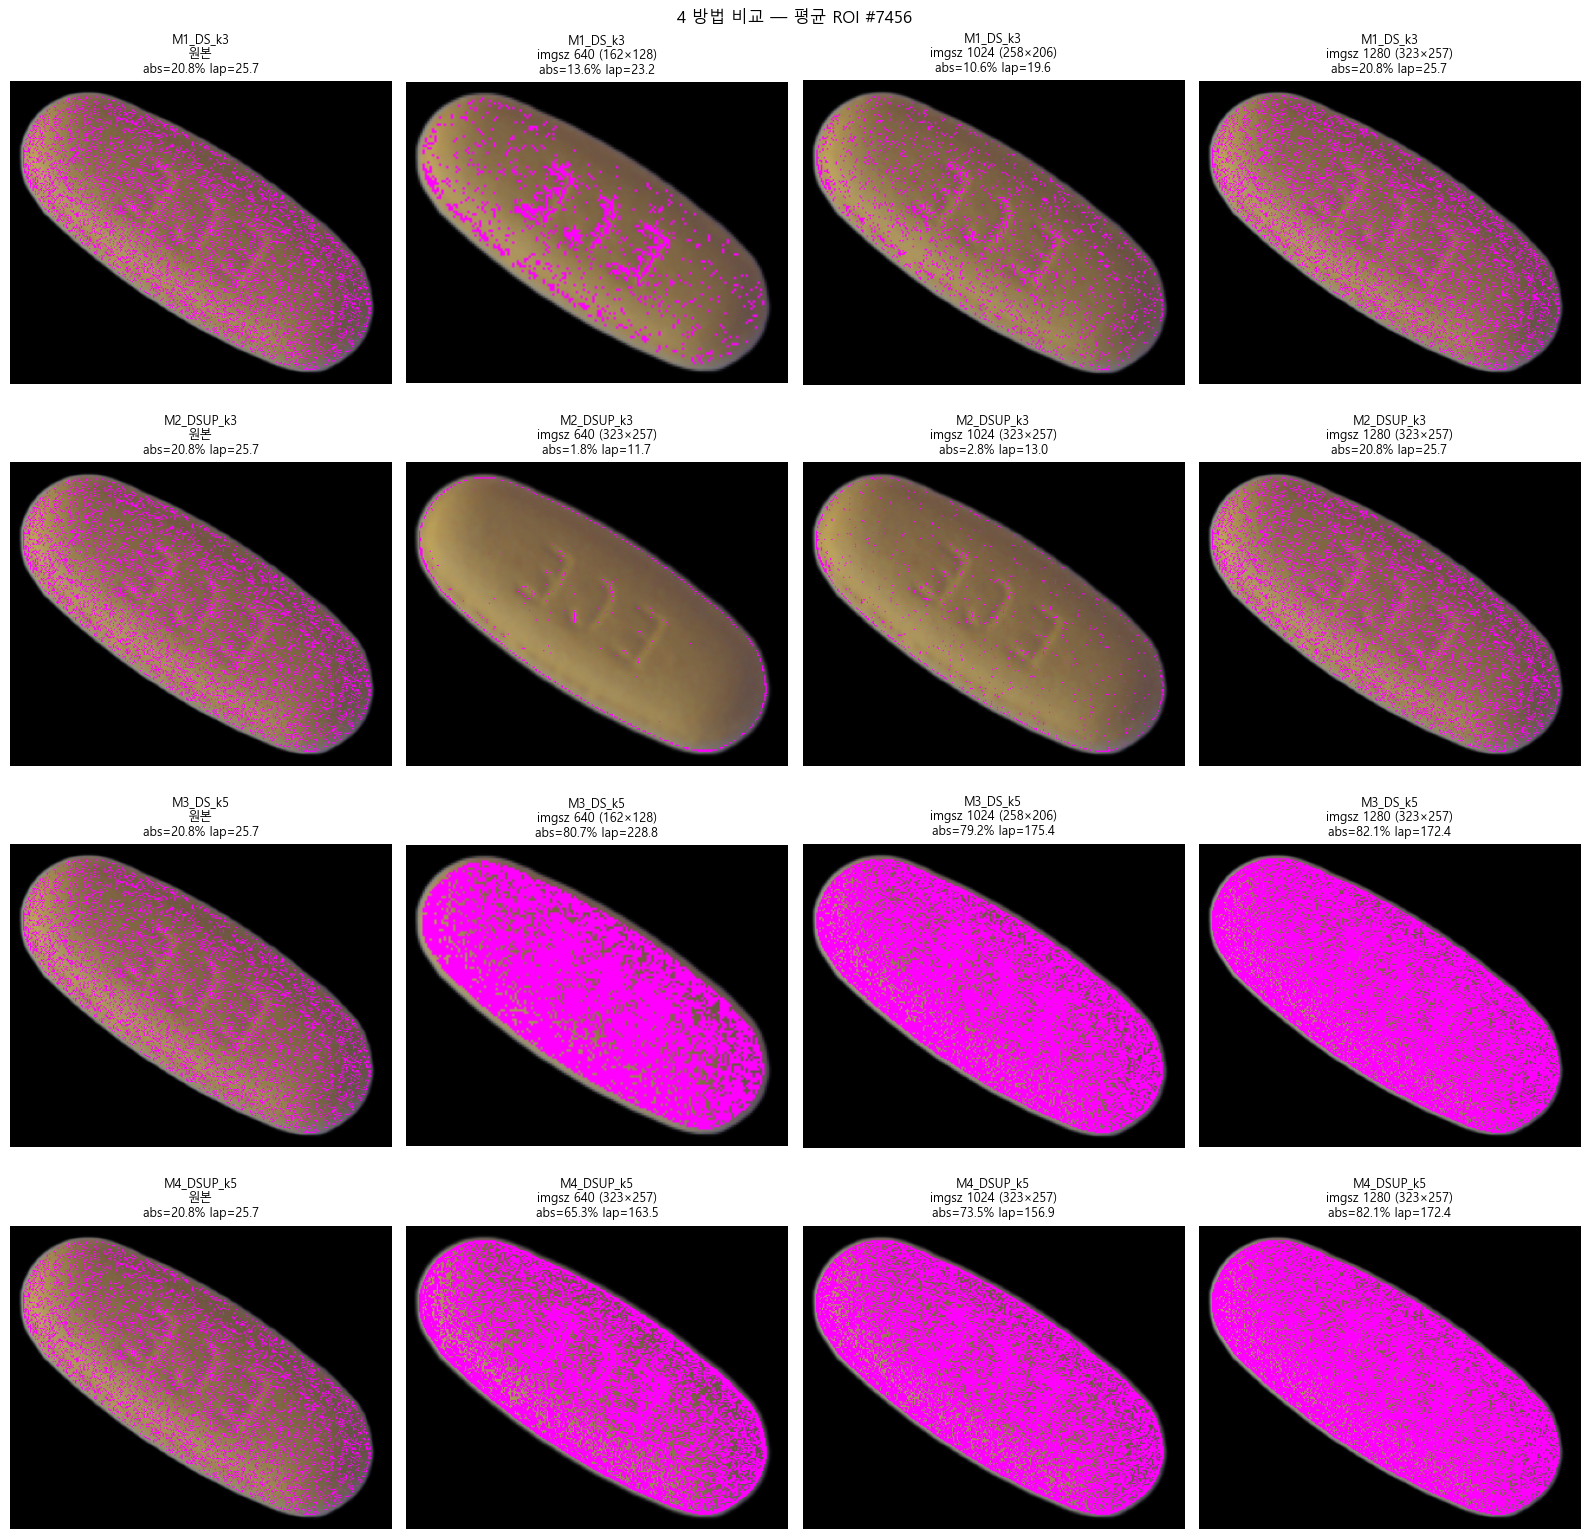


저장: D:\pill_detection\analysis\figures\imprint_05_hypothesis_test.png


In [8]:
## 셀 11 — 의심 가설 4가지 동시 검증

# ── 측정 함수 (ksize 가변) ──
def measure_with_ksize(rgba, abs_threshold, ksize=3, percentile=90, erode_iter=2):
    rgb = rgba[:, :, :3]
    alpha_raw = (rgba[:, :, 3] > 128).astype(np.uint8)
    kernel = np.ones((3, 3), np.uint8)
    alpha = cv2.erode(alpha_raw, kernel, iterations=erode_iter).astype(bool)

    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    lap = cv2.Laplacian(gray, cv2.CV_32F, ksize=ksize)
    lap_abs = np.abs(lap)

    pill_px = int(alpha.sum())
    if pill_px == 0:
        return {'pill_px': 0, 'ratio_pct': 0.0, 'ratio_abs': 0.0, 'mean_lap': 0.0,
                'mask_pct': np.zeros_like(alpha), 'mask_abs': np.zeros_like(alpha)}

    pill_lap = lap_abs[alpha]
    pct_thr = np.percentile(pill_lap, percentile)
    mask_pct = (lap_abs >= pct_thr) & alpha
    mask_abs = (lap_abs >= abs_threshold) & alpha

    return {
        'pill_px': pill_px,
        'ratio_pct': mask_pct.sum() / pill_px,
        'ratio_abs': mask_abs.sum() / pill_px,
        'mean_lap': float(lap_abs[mask_pct].mean()) if mask_pct.any() else 0.0,
        'mask_pct': mask_pct, 'mask_abs': mask_abs,
    }


# ── 4 방법 정의 ──
def method_M1(pil_orig, scale, ksize_orig, ksize_ds):
    """다운샘플만 + ksize_ds로 측정"""
    arr = np.array(pil_orig)
    h, w = arr.shape[:2]
    nw, nh = max(1, int(round(w*scale))), max(1, int(round(h*scale)))
    rgba_ds = cv2.resize(arr, (nw, nh), interpolation=cv2.INTER_AREA)
    return measure_with_ksize(rgba_ds, ABS_THRESHOLD, ksize=ksize_ds), rgba_ds

def method_M2(pil_orig, scale, ksize_orig, ksize_ds):
    """다운→업 + ksize_ds로 원본 해상도에서 측정"""
    arr = np.array(pil_orig)
    h, w = arr.shape[:2]
    nw, nh = max(1, int(round(w*scale))), max(1, int(round(h*scale)))
    rgba_ds = cv2.resize(arr, (nw, nh), interpolation=cv2.INTER_AREA)
    rgba_up = cv2.resize(rgba_ds, (w, h), interpolation=cv2.INTER_LINEAR)
    return measure_with_ksize(rgba_up, ABS_THRESHOLD, ksize=ksize_ds), rgba_up


METHODS = {
    'M1_DS_k3':    lambda p, s: method_M1(p, s, 3, 3),
    'M2_DSUP_k3':  lambda p, s: method_M2(p, s, 3, 3),
    'M3_DS_k5':    lambda p, s: method_M1(p, s, 3, 5),
    'M4_DSUP_k5':  lambda p, s: method_M2(p, s, 3, 5),
}


# ── 측정 ──
hypothesis_results = []

for label, k, v in CHECK_ROIS:
    pil_orig = v['img']
    rgba_orig = pil_to_rgba(pil_orig)
    m_orig = measure_with_ksize(rgba_orig, ABS_THRESHOLD, ksize=3)
    base_pct = m_orig['ratio_pct']
    base_abs = m_orig['ratio_abs']
    base_mean = m_orig['mean_lap']

    for method_name, method_fn in METHODS.items():
        for imgsz, scale in DOWNSAMPLE_TARGETS.items():
            m_ds, _ = method_fn(pil_orig, scale)
            hypothesis_results.append({
                'roi': label, 'key': k, 'method': method_name, 'imgsz': imgsz,
                'pct_%': round(m_ds['ratio_pct']*100, 2),
                'abs_%': round(m_ds['ratio_abs']*100, 2),
                'lap': round(m_ds['mean_lap'], 2),
                'pct_pres': round(m_ds['ratio_pct']/base_pct*100, 1) if base_pct>0 else 0,
                'abs_pres': round(m_ds['ratio_abs']/base_abs*100, 1) if base_abs>0 else 0,
                'lap_pres': round(m_ds['mean_lap']/base_mean*100, 1) if base_mean>0 else 0,
            })


df_hyp = pd.DataFrame(hypothesis_results)
print("[4 방법 × 2 ROI × 3 imgsz 측정]")
print(df_hyp.to_string(index=False))


# ── 단조성 자동 체크 ──
print("\n[단조 감소 체크 — imgsz 640 < 1024 < 1280 순으로 보존율↑이어야 함]")
print("ROI / method / abs_pres / lap_pres / 판정")

monotonic_summary = []
for label, k, _ in CHECK_ROIS:
    for method_name in METHODS:
        sub = df_hyp[(df_hyp['roi']==label) & (df_hyp['method']==method_name)].sort_values('imgsz')
        abs_v = sub['abs_pres'].tolist()
        lap_v = sub['lap_pres'].tolist()
        abs_mono = all(abs_v[i] <= abs_v[i+1] for i in range(len(abs_v)-1))
        lap_mono = all(lap_v[i] <= lap_v[i+1] for i in range(len(lap_v)-1))
        verdict = '✓ 둘 다 단조' if (abs_mono and lap_mono) else \
                  '△ abs만 단조' if abs_mono else \
                  '△ lap만 단조' if lap_mono else \
                  '✗ 둘 다 비단조'
        print(f"  {label} #{k} / {method_name}: abs {abs_v} | lap {lap_v} → {verdict}")
        monotonic_summary.append({
            'roi': label, 'method': method_name,
            'abs_mono': abs_mono, 'lap_mono': lap_mono,
            'verdict': verdict,
        })


# ── 시각: 평균 ROI에서 4 방법 × 3 imgsz (12 패널, abs 마스크 오버레이) ──
fig, axes = plt.subplots(4, 4, figsize=(16, 16))
label_avg, k_avg, v_avg = CHECK_ROIS[1]
pil_avg = v_avg['img']
rgba_avg_orig = pil_to_rgba(pil_avg)
m_avg_orig = measure_with_ksize(rgba_avg_orig, ABS_THRESHOLD, ksize=3)

for row, (method_name, method_fn) in enumerate(METHODS.items()):
    overlay = rgba_avg_orig[:, :, :3].copy()
    overlay[m_avg_orig['mask_abs']] = [255, 0, 255]
    axes[row, 0].imshow(overlay)
    axes[row, 0].set_title(f"{method_name}\n원본\n"
                           f"abs={m_avg_orig['ratio_abs']*100:.1f}% lap={m_avg_orig['mean_lap']:.1f}",
                           fontsize=9)
    axes[row, 0].axis('off')

    for col, (imgsz, scale) in enumerate(DOWNSAMPLE_TARGETS.items(), start=1):
        m_ds, rgba_view = method_fn(pil_avg, scale)
        overlay = rgba_view[:, :, :3].copy()
        overlay[m_ds['mask_abs']] = [255, 0, 255]
        axes[row, col].imshow(overlay)
        axes[row, col].set_title(f"{method_name}\nimgsz {imgsz} ({rgba_view.shape[1]}×{rgba_view.shape[0]})\n"
                                 f"abs={m_ds['ratio_abs']*100:.1f}% lap={m_ds['mean_lap']:.1f}",
                                 fontsize=9)
        axes[row, col].axis('off')

plt.suptitle(f"4 방법 비교 — 평균 ROI #{k_avg}", fontsize=12)
plt.tight_layout()

out = FIG_DIR / "imprint_05_hypothesis_test.png"
plt.savefig(out, dpi=120, bbox_inches='tight')
plt.show()
print(f"\n저장: {out}")

## 6. M2 측정 일반성 검증 — 평균 크기 ROI 5장 시각

이전 셀에서 평균 ROI #7456의 M2 시각이 단조 패턴 보임 (원본 표면 노이즈 → 다운→업 후 ECE 글자 드러남). 1장만으로는 일반화 불가.

평균 크기 근처(area ≈ 268×319 = 85,492 ±) ROI 5장 무작위 추출. 각각 원본 vs M2 imgsz 640 시각 비교. 단조 패턴이 일관되게 나타나는지 확인.

각인 측정값(abs/lap) 동시 출력해서 시각과 수치 일치 검증.

[검증 ROI 5장] (평균 크기 ≈ 268×319 근접 풀에서)
  #5688: 349×252
  #2639: 329×256
  #1500: 219×392
  #3278: 212×410
  #3005: 331×264
  #5688: abs 22.6% → 4.0% (18%) | lap 29.3 → 17.1 (59%)
  #2639: abs 20.8% → 1.4% (7%) | lap 26.1 → 11.4 (44%)
  #1500: abs 23.8% → 5.4% (23%) | lap 29.1 → 17.7 (61%)
  #3278: abs 26.7% → 5.1% (19%) | lap 31.1 → 17.0 (55%)
  #3005: abs 20.0% → 1.3% (7%) | lap 25.8 → 11.2 (44%)


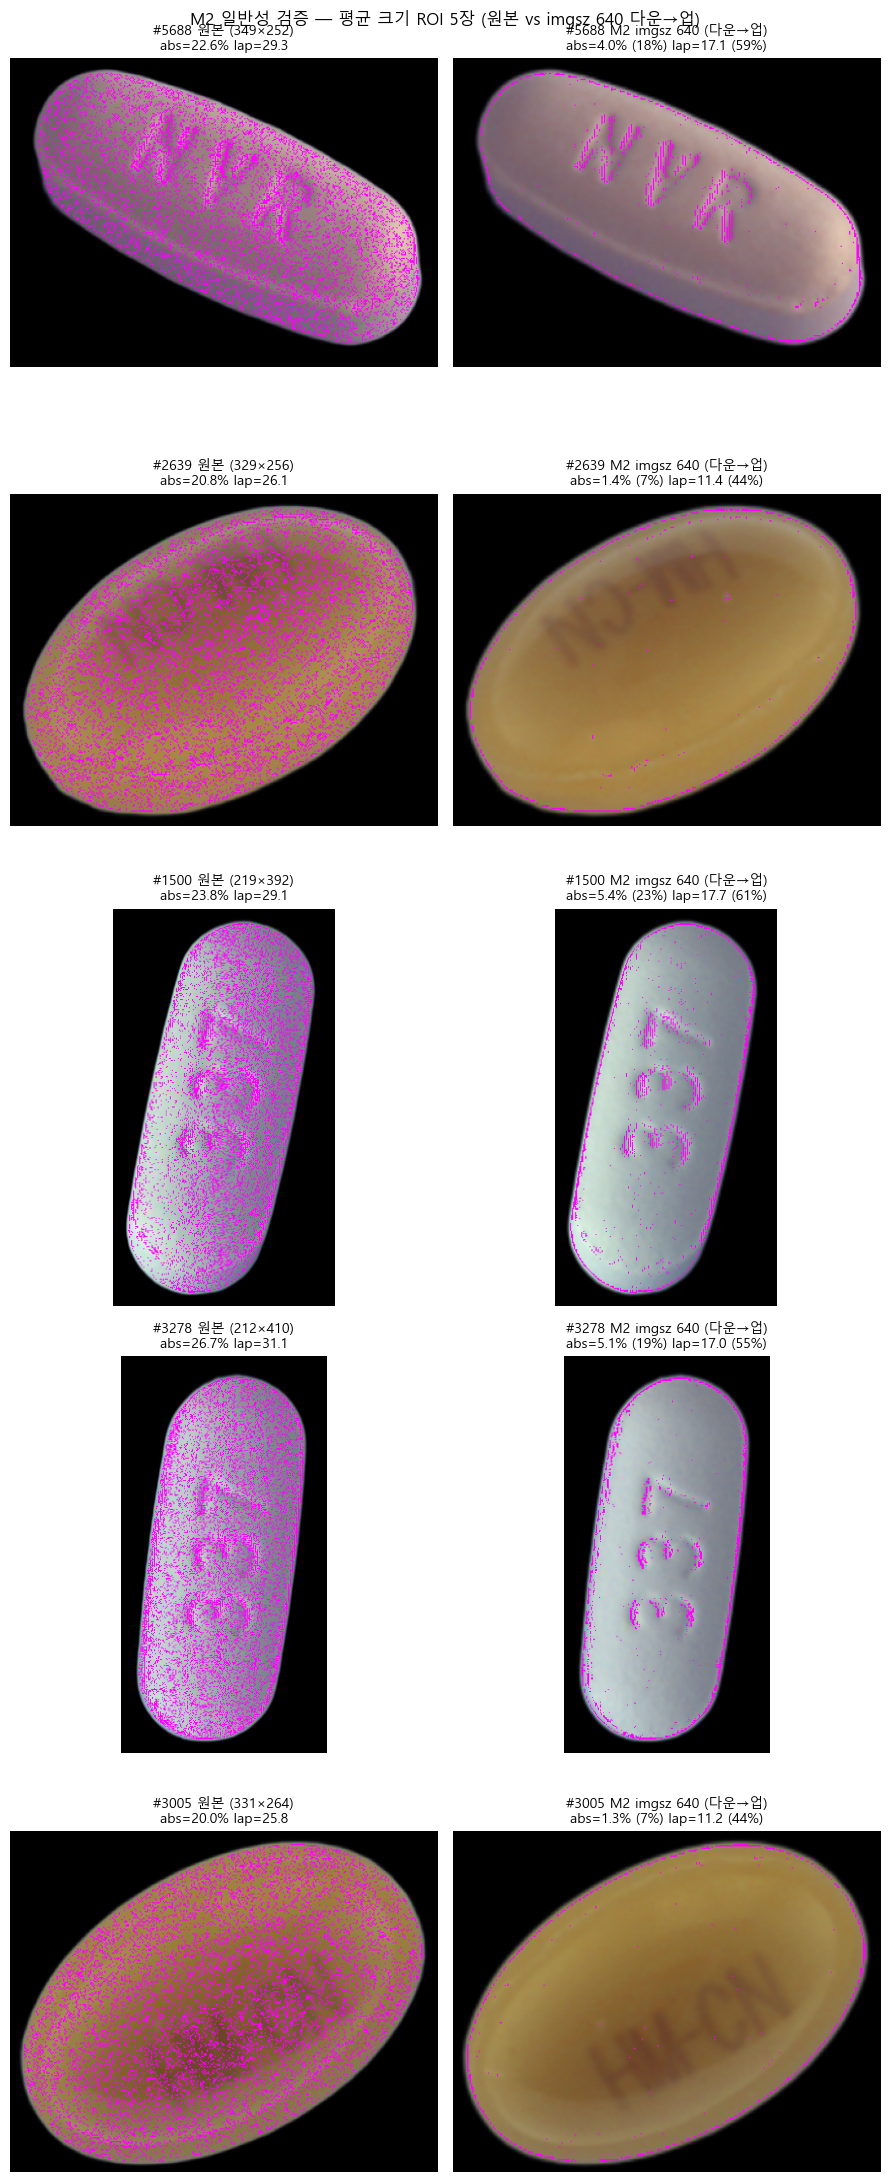


저장: D:\pill_detection\analysis\figures\imprint_06_m2_generality.png


In [9]:
## 셀 13 — M2 일반성 검증 (평균 크기 ROI 5장 시각)

# 평균 크기 근접 200개 풀에서 5개 무작위 추출 (#7456 제외)
N_CHECK = 5
SEED_B = 99
rng_b = np.random.default_rng(SEED_B)

# 평균 ROI 풀에서 #7456 제외
pool_keys = [k for k, v, _ in items_close_to_avg if k != avg_key]
pool_items_dict = {k: v for k, v, _ in items_close_to_avg if k != avg_key}
chosen_5 = rng_b.choice(len(pool_keys), N_CHECK, replace=False)
selected = [(pool_keys[i], pool_items_dict[pool_keys[i]]) for i in chosen_5]

print(f"[검증 ROI 5장] (평균 크기 ≈ 268×319 근접 풀에서)")
for k, v in selected:
    print(f"  #{k}: {v['w']}×{v['h']}")


# ── 시각 + 측정 (M2, imgsz 640) ──
TARGET_IMGSZ = 640
target_scale = DOWNSAMPLE_TARGETS[TARGET_IMGSZ]

fig, axes = plt.subplots(N_CHECK, 2, figsize=(9, 4.5*N_CHECK))

for row, (k, v) in enumerate(selected):
    pil_orig = v['img']
    rgba_orig = pil_to_rgba(pil_orig)
    h, w = rgba_orig.shape[:2]

    # 원본 측정 (ksize 3)
    m_orig = measure_with_ksize(rgba_orig, ABS_THRESHOLD, ksize=3)
    overlay_orig = rgba_orig[:, :, :3].copy()
    overlay_orig[m_orig['mask_abs']] = [255, 0, 255]

    axes[row, 0].imshow(overlay_orig)
    axes[row, 0].set_title(f"#{k} 원본 ({w}×{h})\n"
                           f"abs={m_orig['ratio_abs']*100:.1f}% lap={m_orig['mean_lap']:.1f}",
                           fontsize=10)
    axes[row, 0].axis('off')

    # M2: 다운→업, ksize 3
    nw, nh = max(1, int(round(w*target_scale))), max(1, int(round(h*target_scale)))
    arr = np.array(pil_orig)
    rgba_ds = cv2.resize(arr, (nw, nh), interpolation=cv2.INTER_AREA)
    rgba_up = cv2.resize(rgba_ds, (w, h), interpolation=cv2.INTER_LINEAR)
    m_m2 = measure_with_ksize(rgba_up, ABS_THRESHOLD, ksize=3)
    overlay_m2 = rgba_up[:, :, :3].copy()
    overlay_m2[m_m2['mask_abs']] = [255, 0, 255]

    abs_pres = m_m2['ratio_abs']/m_orig['ratio_abs']*100 if m_orig['ratio_abs']>0 else 0
    lap_pres = m_m2['mean_lap']/m_orig['mean_lap']*100 if m_orig['mean_lap']>0 else 0

    axes[row, 1].imshow(overlay_m2)
    axes[row, 1].set_title(f"#{k} M2 imgsz {TARGET_IMGSZ} (다운→업)\n"
                           f"abs={m_m2['ratio_abs']*100:.1f}% ({abs_pres:.0f}%) "
                           f"lap={m_m2['mean_lap']:.1f} ({lap_pres:.0f}%)",
                           fontsize=10)
    axes[row, 1].axis('off')

    print(f"  #{k}: abs {m_orig['ratio_abs']*100:.1f}% → {m_m2['ratio_abs']*100:.1f}% ({abs_pres:.0f}%) | "
          f"lap {m_orig['mean_lap']:.1f} → {m_m2['mean_lap']:.1f} ({lap_pres:.0f}%)")

plt.suptitle(f"M2 일반성 검증 — 평균 크기 ROI 5장 (원본 vs imgsz {TARGET_IMGSZ} 다운→업)", fontsize=12)
plt.tight_layout()

out = FIG_DIR / "imprint_06_m2_generality.png"
plt.savefig(out, dpi=120, bbox_inches='tight')
plt.show()
print(f"\n저장: {out}")

## 7. 100 ROI 통계 — 처방 1 imgsz 결정

5장 검증으로 M2 측정 단조성 확인. 이제 cache 7503 중 100 ROI 무작위 추출 → 분포 측정.

**측정 방법**:
- M2 (다운→업, ksize 3) 확정
- imgsz 640 / 1024 / 1280 각각 측정
- 보존율 = (다운→업 후 값) / (원본 값)

**3개 지표**:
- abs_preservation: 절대 임계 마스크 픽셀 비율 보존율
- lap_preservation: percentile 마스크 위치의 평균 lap_abs 보존율 (각인 강도)
- pct_preservation: percentile 마스크 픽셀 비율 보존율 (참고용, 상대 임계라 둔감)

**시각화**: imgsz별 보존율 분포 boxplot + violin. mean / median / 25/75 percentile 출력.

**의사결정 기준**:
- imgsz 1024 vs 1280의 lap_preservation 분포가 의미있게 다른가
- 1024로 충분한가, 1280이 필요한가
- A100 메모리/시간 트레이드오프는 별도 고려 (여기선 정보 손실만)

[샘플링] cache 7503 중 100개 (seed=2026)
  20/100 완료
  40/100 완료
  60/100 완료
  80/100 완료
  100/100 완료

측정 완료: 300행 (100 ROI × 3 imgsz)

[imgsz별 보존율 분포]
 imgsz |     metric |    mean  median    std |    p25    p75 |    min    max
----------------------------------------------------------------------------------------
   640 |   abs_pres |    26.7    22.7   18.6 |   11.1   38.4 |    2.8   80.5
   640 |   lap_pres |    62.1    60.0   17.8 |   47.0   76.7 |   33.0  100.8
   640 |   pct_pres |   111.4   108.3   21.9 |   95.4  130.7 |   72.9  185.1

  1024 |   abs_pres |    33.4    31.2   16.9 |   18.4   42.5 |   10.0   82.1
  1024 |   lap_pres |    65.5    62.4   12.6 |   54.8   74.7 |   46.4   98.0
  1024 |   pct_pres |   110.9   108.9   17.7 |   99.0  122.3 |   65.1  172.5

  1280 |   abs_pres |   100.0   100.0    0.0 |  100.0  100.0 |  100.0  100.0
  1280 |   lap_pres |   100.0   100.0    0.0 |  100.0  100.0 |  100.0  100.0
  1280 |   pct_pres |   100.0   100.0    0.0 |  100.0  100.0 |  100.0

C:\Users\tran6\AppData\Local\Temp\ipykernel_4100\2048273060.py:100: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f'imgsz\n{sz}' for sz in DOWNSAMPLE_TARGETS],
C:\Users\tran6\AppData\Local\Temp\ipykernel_4100\2048273060.py:100: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f'imgsz\n{sz}' for sz in DOWNSAMPLE_TARGETS],
C:\Users\tran6\AppData\Local\Temp\ipykernel_4100\2048273060.py:100: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f'imgsz\n{sz}' for sz in DOWNSAMPLE_TARGETS],


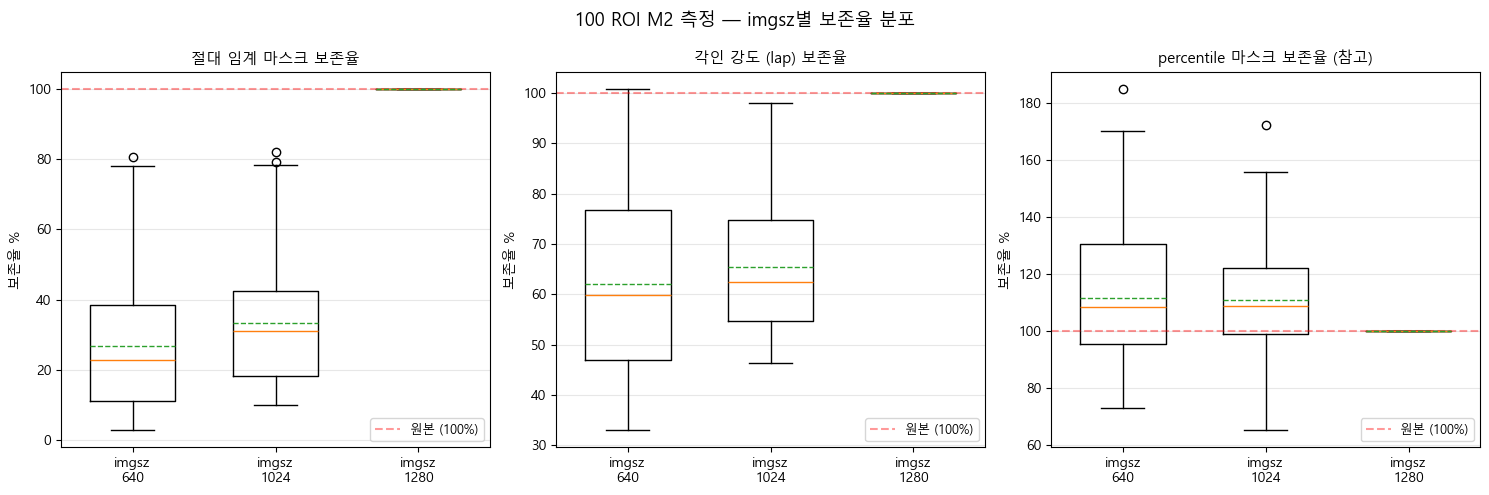


저장: D:\pill_detection\analysis\figures\imprint_07_100roi_distribution.png


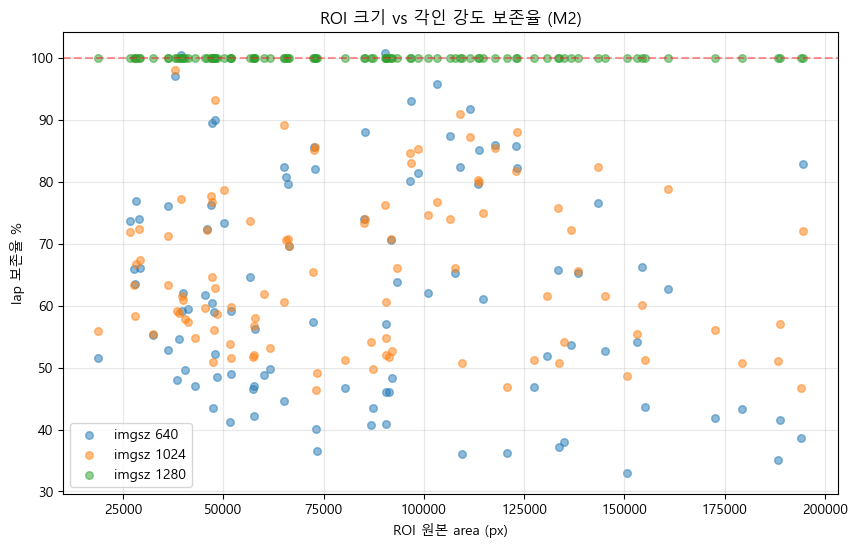

저장: D:\pill_detection\analysis\figures\imprint_08_area_vs_preservation.png


In [10]:
## 셀 15 — 100 ROI M2 통계

N_SAMPLE = 100
SEED_C = 2026

rng_c = np.random.default_rng(SEED_C)
sample_idx = rng_c.choice(len(items), N_SAMPLE, replace=False)
print(f"[샘플링] cache 7503 중 {N_SAMPLE}개 (seed={SEED_C})")


# ── M2 측정 함수 (간결화) ──
def measure_m2(pil_orig, scale, abs_threshold, ksize=3):
    arr = np.array(pil_orig)
    h, w = arr.shape[:2]
    nw, nh = max(1, int(round(w*scale))), max(1, int(round(h*scale)))
    rgba_ds = cv2.resize(arr, (nw, nh), interpolation=cv2.INTER_AREA)
    rgba_up = cv2.resize(rgba_ds, (w, h), interpolation=cv2.INTER_LINEAR)
    return measure_with_ksize(rgba_up, abs_threshold, ksize=ksize)


# ── 100 ROI × 3 imgsz 측정 ──
records = []
for i, idx in enumerate(sample_idx):
    k, v = items[idx]
    pil_orig = v['img']
    rgba_orig = pil_to_rgba(pil_orig)
    h, w = rgba_orig.shape[:2]
    area = w * h

    m_orig = measure_with_ksize(rgba_orig, ABS_THRESHOLD, ksize=3)
    base_pct = m_orig['ratio_pct']
    base_abs = m_orig['ratio_abs']
    base_lap = m_orig['mean_lap']

    if base_lap == 0 or base_abs == 0:
        # 알약 없는/비정상 ROI 스킵
        continue

    for imgsz, scale in DOWNSAMPLE_TARGETS.items():
        m_ds = measure_m2(pil_orig, scale, ABS_THRESHOLD, ksize=3)
        records.append({
            'roi_key': k, 'class_idx': v.get('class_idx', -1),
            'orig_w': w, 'orig_h': h, 'area': area,
            'imgsz': imgsz,
            'orig_abs_%': base_abs * 100,
            'orig_lap': base_lap,
            'pct_pres_%': m_ds['ratio_pct']/base_pct*100 if base_pct>0 else 0,
            'abs_pres_%': m_ds['ratio_abs']/base_abs*100,
            'lap_pres_%': m_ds['mean_lap']/base_lap*100,
        })

    if (i+1) % 20 == 0:
        print(f"  {i+1}/{N_SAMPLE} 완료")

df_stat = pd.DataFrame(records)
print(f"\n측정 완료: {len(df_stat)}행 ({len(df_stat)//3} ROI × 3 imgsz)")


# ── imgsz별 분포 통계 ──
print("\n[imgsz별 보존율 분포]")
print(f"{'imgsz':>6} | {'metric':>10} | {'mean':>7} {'median':>7} {'std':>6} | "
      f"{'p25':>6} {'p75':>6} | {'min':>6} {'max':>6}")
print("-" * 88)
for imgsz in DOWNSAMPLE_TARGETS:
    sub = df_stat[df_stat['imgsz']==imgsz]
    for metric, col in [('abs_pres', 'abs_pres_%'), ('lap_pres', 'lap_pres_%'), ('pct_pres', 'pct_pres_%')]:
        vals = sub[col]
        print(f"{imgsz:>6} | {metric:>10} | "
              f"{vals.mean():>7.1f} {vals.median():>7.1f} {vals.std():>6.1f} | "
              f"{vals.quantile(.25):>6.1f} {vals.quantile(.75):>6.1f} | "
              f"{vals.min():>6.1f} {vals.max():>6.1f}")
    print()


# ── imgsz 1024 vs 1280 차이 정량 (페어 비교) ──
print("[imgsz 1024 vs 1280 페어 비교 — 같은 ROI에서 직접 비교]")
piv_lap = df_stat.pivot(index='roi_key', columns='imgsz', values='lap_pres_%')
piv_abs = df_stat.pivot(index='roi_key', columns='imgsz', values='abs_pres_%')

diff_lap_1024_1280 = piv_lap[1280] - piv_lap[1024]
diff_abs_1024_1280 = piv_abs[1280] - piv_abs[1024]
diff_lap_640_1024 = piv_lap[1024] - piv_lap[640]
diff_abs_640_1024 = piv_abs[1024] - piv_abs[640]

print(f"  lap_pres: 1280 - 1024 = mean {diff_lap_1024_1280.mean():.1f}, median {diff_lap_1024_1280.median():.1f}")
print(f"  abs_pres: 1280 - 1024 = mean {diff_abs_1024_1280.mean():.1f}, median {diff_abs_1024_1280.median():.1f}")
print(f"  lap_pres: 1024 -  640 = mean {diff_lap_640_1024.mean():.1f}, median {diff_lap_640_1024.median():.1f}")
print(f"  abs_pres: 1024 -  640 = mean {diff_abs_640_1024.mean():.1f}, median {diff_abs_640_1024.median():.1f}")


# ── 시각화: boxplot 3개 (abs / lap / pct) ──
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
metrics = [
    ('abs_pres_%', '절대 임계 마스크 보존율'),
    ('lap_pres_%', '각인 강도 (lap) 보존율'),
    ('pct_pres_%', 'percentile 마스크 보존율 (참고)'),
]
for ax, (col, title) in zip(axes, metrics):
    data = [df_stat[df_stat['imgsz']==sz][col].values for sz in DOWNSAMPLE_TARGETS]
    bp = ax.boxplot(data, labels=[f'imgsz\n{sz}' for sz in DOWNSAMPLE_TARGETS],
                    showmeans=True, meanline=True, widths=0.6)
    ax.axhline(100, color='red', linestyle='--', alpha=0.4, label='원본 (100%)')
    ax.set_title(title, fontsize=11)
    ax.set_ylabel('보존율 %')
    ax.grid(alpha=0.3, axis='y')
    ax.legend(loc='lower right', fontsize=9)

plt.suptitle(f"100 ROI M2 측정 — imgsz별 보존율 분포", fontsize=13)
plt.tight_layout()

out = FIG_DIR / "imprint_07_100roi_distribution.png"
plt.savefig(out, dpi=120, bbox_inches='tight')
plt.show()
print(f"\n저장: {out}")


# ── ROI 크기 의존성 — area별 lap_pres scatter ──
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
for imgsz in DOWNSAMPLE_TARGETS:
    sub = df_stat[df_stat['imgsz']==imgsz]
    ax.scatter(sub['area'], sub['lap_pres_%'], alpha=0.5, label=f'imgsz {imgsz}', s=30)
ax.axhline(100, color='red', linestyle='--', alpha=0.4)
ax.set_xlabel('ROI 원본 area (px)')
ax.set_ylabel('lap 보존율 %')
ax.set_title('ROI 크기 vs 각인 강도 보존율 (M2)')
ax.legend()
ax.grid(alpha=0.3)

out2 = FIG_DIR / "imprint_08_area_vs_preservation.png"
plt.savefig(out2, dpi=120, bbox_inches='tight')
plt.show()
print(f"저장: {out2}")

## 8. 종합 — 처방 1 정량 결정

### 측정 결과 (100 ROI, M2 방법)

| imgsz | lap_pres mean | abs_pres mean | lap std |
|---|---|---|---|
| 640 | 62.1% | 26.7% | 17.8 |
| 1024 | 65.5% | 33.4% | 12.6 |
| 1280 | 100.0% | 100.0% | 0 |

페어 비교 (같은 ROI):
- 640 → 1024: lap +3.4, abs +6.7
- 1024 → 1280: lap +34.5, abs +66.6

### 처방 1 권고

**imgsz 1280.** 1024와 640의 lap 보존율 차이는 3.4%p로 미미, 1280에서만 의미 있는 점프 발생.

### 측정 한계

1. 합성 long side가 1280이라 imgsz 1280 = 원본 = 자동 100%. 본 측정은 "현재 합성 환경에서 imgsz별 손실"이며, 합성 자체를 더 크게(예: 1600+) 만들면 imgsz 1280에서도 손실 발생.
2. Laplacian 보존율과 학습 모델 분류 성능의 인과 관계는 본 노트북에서 측정 안 함.
3. cache 평균 268×319 기준 측정. 다른 크기 분포에서는 패턴 다를 수 있음.

### 의사결정 영향

- 학습 노트북: imgsz 1280
- A100 메모리 한계 시 batch 16 → 8
- 합성 데이터 long side 1280 유지

### 산출 figure

- imprint_01_definition.png — 각인 픽셀 정의
- imprint_02_downsample_single.png — 단일 ROI 다운샘플
- imprint_03_dual_measure.png — Dual 임계 측정
- imprint_04_resize_method.png — resize 방법 비교
- imprint_05_hypothesis_test.png — 4 방법 의심 가설 검증
- imprint_06_m2_generality.png — M2 일반성 5장
- imprint_07_100roi_distribution.png — 100 ROI 분포 (핵심)
- imprint_08_area_vs_preservation.png — ROI 크기 vs 보존율